<a href="https://colab.research.google.com/github/SantiagoPinedaM/BI/blob/main/Reto_1_Int_de_Datos_y_Prosp_Santiago_Pineda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

RETO 1: SANTIAGO PINEDA MEJIA

Se quiere caracterizar (Media,Varianza, Asimetria y Kurtosis) la distribucion agregada de perdidas como resultado de las perdidas asociadas a los creditos que posee un FINTECH . Las variables que definen la Loss Distribution Aproach (LDA) Se obtiene del producto de las siguientes variables:

Monto (EAD): Es el monto de dinero que una persona solicita a la FINTECH
Probabilidad default (PD): Es la probablidad de que una persona incumpla el credito a lo largo de su vigencia
Loss Guarantee Default (LGD): La garantia que el solicitante puede colocar sobre el credito

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns #Gráfico de distribuciones


# Path to your file
file_path = '/content/sample_data/1. SolicitantesCrédito(USD)_Años.xlsx'

# **Solicitantes Credito Año 4**

In [ ]:
nxl='/content/1. SolicitantesCrédito(USD)_Años.xlsx'
XDB=pd.read_excel(nxl,sheet_name=2)

XDB.head()

,Unnamed: 0,Edad,Sexo,Estado civil,Hijos,Perscargo,Nivel Renta,Estrato,Nivel de estudios,Tipo de contrato,...,Plazo,Cuota (COP),ConoCliente,Garantia,RespPat,MoraCome,PreApr,Prob.Default (PD),Score,LGD
0,1,38,NR,Casado,1,0,0,3,Bachiller,Ninguno,...,48,18.375890,Buenas Referencias,Sin Codeudor,Sin Patrimonio,Con Experiencia sin Mora,1,0.041659,582.478943,0.168536
1,2,51,NR,Separado,6,1,1,4,Técnico,Ninguno,...,36,5.062492,Buenas Referencias,Sin Codeudor,Prop.sin Hipoteca,Con Experiencia sin Mora,1,0.234951,479.839966,0.173085
2,3,37,Mujer,Casado,2,0,0,3,Tecnólogo,Indefinido,...,36,10.287688,Buenas Referencias,Con Codeudor(es),Sin Patrimonio,Con Experiencia sin Mora,0,0.170330,417.653107,0.082779
3,4,29,NR,Separado,1,0,0,2,Tecnólogo,Ninguno,...,24,15.458878,Buenas Referencias,Con Codeudor(es),Sin Patrimonio,Con Experiencia sin Mora,1,0.201659,316.791107,0.463798
4,5,42,Mujer,Casado,3,4,4,2,Especializacion,Ninguno,...,24,24.995180,Buenas Referencias,Con Codeudor(es),Sin Patrimonio,Con Experiencia sin Mora,1,0.140929,441.809570,0.160611


In [ ]:
#Distribucion LDA
LDA=XDB.iloc[:,25]*XDB.iloc[:,33]*(1+XDB.iloc[:,35])
display(LDA)

,0
0,30.452702
1,38.595235
2,52.482156
3,91.404252
4,81.890611
...,...
1495,24.255075
1496,17.120129
1497,64.668290
1498,85.242859


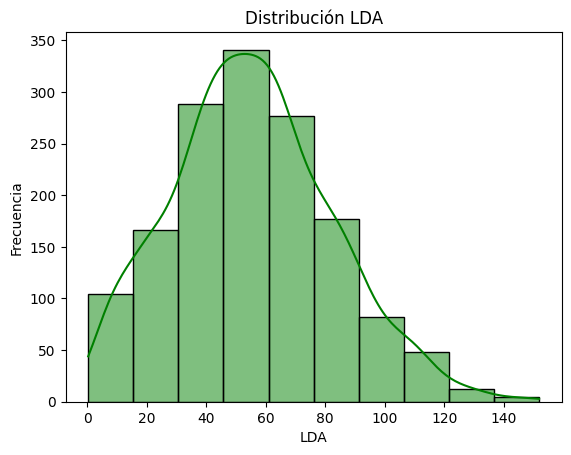

,LI,LS,ND,perdida
0,0.354255,15.502616,104.0,7.928435
1,15.502616,30.650978,166.0,23.076797
2,30.650978,45.799339,288.0,38.225159
3,45.799339,60.947701,341.0,53.373520
4,60.947701,76.096063,277.0,68.521882
5,76.096063,91.244424,177.0,83.670243
6,91.244424,106.392786,82.0,98.818605
7,106.392786,121.541148,48.0,113.966967
8,121.541148,136.689509,12.0,129.115328
9,136.689509,151.837871,5.0,144.263690


In [ ]:
#Gráficar la distribución LDA
NC=10

plt.figure()
sns.histplot(LDA,kde=True,bins=NC,color='green')
plt.title('Distribución LDA')
plt.xlabel('LDA')
plt.ylabel('Frecuencia')
plt.show()

#Obtenemos la informacion de la Distribucion
counts, bin_edges = np.histogram(LDA, bins=NC)
LI =bin_edges[:-1];LS= bin_edges[1:]
mc=(LI+LS)/2 #Valor representativo de cada intervalo

#Se crea la tabla de caracterización
TAsq=np.column_stack((LI,LS,counts,mc))
df=pd.DataFrame(TAsq,columns=['LI','LS','ND','perdida'])
display(df)

Se obtiene las medidas de dispercion y tendecia central (Media, Varianza, Desviacion)

In [ ]:
u=np.sum(mc*counts)/np.sum(counts)
print("La media de los datos es: ", u) #Valor esperado

varianza=np.sum(counts*(mc-u)**2)/np.sum(counts)
print("La varianza de los datos es: ",varianza)

desviacion=np.sqrt(varianza)
print("La desviacion de los datos es: ",desviacion)

La media de los datos es:  55.66597231387269
La varianza de los datos es:  738.0837467102078
La desviacion de los datos es:  27.167696750188593


In [ ]:
import scipy.stats as stats
from scipy.stats import skew

In [ ]:
#Identificar datos raros o outliers
LIe=u-2*desviacion;LSe=u+2*desviacion
filas_out=np.where((LDA<LIe)|(LDA>LSe))[0]
print('Los coeficiente de outliers son:',filas_out)

from scipy.stats import skew, kurtosis
print('El coeficiente de asimetria es:',skew(LDA))
print('El coeficiente de curtosis es:',kurtosis(LDA))

Los coeficiente de outliers son: [  25   32   52   71  114  155  259  294  335  342  361  373  386  388
  394  407  435  529  532  537  540  639  660  700  733  735  747  775
  813  829  853  912  916  926  945  948  970  985  998 1016 1048 1049
 1084 1094 1175 1221 1292 1298 1327 1413]
El coeficiente de asimetria es: 0.3354409078926966
El coeficiente de curtosis es: -0.06285449119370945


In [ ]:
#Coeficiente de asimetria
cas= np.sum(counts*(mc-u)**3)/np.sum(counts*desviacion**3)
print("El coeficiente de asimetria es: ",cas)
vcas=(skew(LDA)-cas)/skew(LDA)
print("El valor de asimetria es: ",vcas*100)

El coeficiente de asimetria es:  0.33970946303261645
El valor de asimetria es:  -1.2725207449311218


In [ ]:
#Coeficiente de Curtosis
curt = np.sum(counts*(mc-u)**4)/np.sum(counts*desviacion**4)-3
print("El coeficiente de curtosis es: ",curt)

El coeficiente de curtosis es:  -0.10378250280685375


In [ ]:
PE=len(np.where(LDA<u)[0])
print('Las perdidas esperadas son:',PE)
PC=len(np.where(LDA>OpVar)[0])
print('Las perdidas catastroficas son:',PC)
PNE=len(np.where((LDA>=u)&(LDA<=OpVar))[0])
print('Las perdidas no esperadas son:',PNE)

Las perdidas esperadas son: 781
Las perdidas catastroficas son: 2
Las perdidas no esperadas son: 717


In [ ]:
OpVar=np.percentile(LDA,99.9)
print('El costo de aseguramiento de cada credito es:',OpVar)

El costo de aseguramiento de cada credito es: 147.29776773898615


# **Solicitantes Credito Año 3**

In [ ]:
nxl='/content/1. SolicitantesCrédito(USD)_Años.xlsx'
XDB2=pd.read_excel(nxl,sheet_name=3)

XDB2.head()

,Unnamed: 0,Edad,Sexo,Estado civil,Hijos,Perscargo,Nivel Renta,Estrato,Nivel de estudios,Tipo de contrato,...,Plazo,Cuota (COP),ConoCliente,Garantia,RespPat,MoraCome,PreApr,Prob.Default (PD),Score,LGD
0,2112,33,Hombre,Casado,0,1,1,4,Técnico,Indefinido,...,18,52.546662,Buenas Referencias,Con Codeudor(es),Prop.sin Hipoteca,Con Experiencia sin Mora,0,0.064700,498.646271,0.005317
1,2115,42,Hombre,Soltero,1,1,1,5,Bachiller,Ninguno,...,18,2.808395,Sin Referencias,Sin Codeudor,Sin Patrimonio,Con Experiencia sin Mora,0,0.297233,371.733276,0.295880
2,2116,34,Hombre,Soltero,0,2,2,2,Bachiller,Indefinido,...,36,10.409358,Buenas Referencias,Con Codeudor(es),Prop.sin Hipoteca,Con Experiencia sin Mora,0,0.122595,418.416077,0.004645
3,2117,47,Hombre,Casado,1,0,0,3,Profesional,Indefinido,...,24,80.445793,Buena Experiencia CFB,Libranza Establecida,Sin Patrimonio,Con Experiencia sin Mora,1,0.034746,593.847656,0.385068
4,2118,67,Mujer,Casado,1,0,0,3,Bachiller,Indefinido,...,36,27.508639,Buena Experiencia CFB,Sin Codeudor,Sin Patrimonio,Con Experiencia sin Mora,1,0.081015,567.578308,0.054015


In [ ]:
#Se calcula la distribucion LDA
LDA=XDB2.iloc[:,25]*XDB2.iloc[:,33]*(1+XDB2.iloc[:,35])
display(LDA)

,0
0,53.566719
1,16.953516
2,35.462688
3,77.548756
4,64.974313
...,...
1496,24.010720
1497,48.948467
1498,18.773132
1499,97.794371


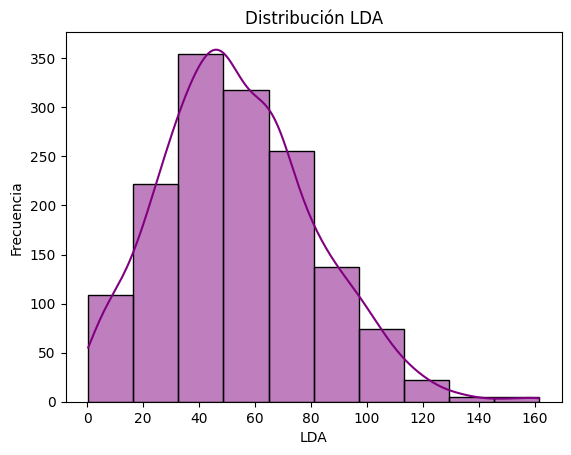

,LI,LS,ND,perdida
0,0.427835,16.545128,109.0,8.486481
1,16.545128,32.662422,222.0,24.603775
2,32.662422,48.779716,354.0,40.721069
3,48.779716,64.897009,318.0,56.838362
4,64.897009,81.014303,255.0,72.955656
5,81.014303,97.131597,137.0,89.072950
6,97.131597,113.248890,74.0,105.190244
7,113.248890,129.366184,22.0,121.307537
8,129.366184,145.483478,5.0,137.424831
9,145.483478,161.600771,5.0,153.542125


In [ ]:
#Gráficar la distribución LDA
NC=10

plt.figure()
sns.histplot(LDA,kde=True,bins=NC,color='purple')
plt.title('Distribución LDA')
plt.xlabel('LDA')
plt.ylabel('Frecuencia')
plt.show()

#Obtenemos la informacion de la Distribucion
counts, bin_edges = np.histogram(LDA, bins=NC)
LI =bin_edges[:-1];LS= bin_edges[1:]
mc=(LI+LS)/2 #Valor representativo de cada intervalo

#Se crea la tabla de caracterización
TAsq=np.column_stack((LI,LS,counts,mc))
df=pd.DataFrame(TAsq,columns=['LI','LS','ND','perdida'])
display(df)

In [ ]:
u=np.sum(mc*counts)/np.sum(counts)
print("La media de los datos es: ", u) #Valor esperado

varianza=np.sum(counts*(mc-u)**2)/np.sum(counts)
print("La varianza de los datos es: ",varianza)

desviacion=np.sqrt(varianza)
print("La desviacion de los datos es: ",desviacion)

La media de los datos es:  54.35795284724899
La varianza de los datos es:  746.4973760157775
La desviacion de los datos es:  27.32210416523181


In [ ]:
#Identificar datos raros o outliers
LIe=u-2*desviacion;LSe=u+2*desviacion
filas_out=np.where((LDA<LIe)|(LDA>LSe))[0]
print('Los coeficiente de outliers son:',filas_out)

from scipy.stats import skew, kurtosis
print('El coeficiente de asimetria es:',skew(LDA))
print('El coeficiente de curtosis es:',kurtosis(LDA))

Los coeficiente de outliers son: [  18   52   58   63  100  104  122  170  207  237  322  352  369  378
  460  496  503  504  593  599  625  671  731  761  765  782  825  836
  874  885  906  964 1018 1024 1029 1039 1083 1117 1151 1161 1192 1193
 1203 1276 1390 1433]
El coeficiente de asimetria es: 0.46219026649218486
El coeficiente de curtosis es: 0.18859622645960705


In [ ]:
#Coeficiente de asimetria
cas= np.sum(counts*(mc-u)**3)/np.sum(counts*desviacion**3)
print("El coeficiente de asimetria es: ",cas)
vcas=(skew(LDA)-cas)/skew(LDA)
print("El valor de asimetria es: ",vcas*100)

El coeficiente de asimetria es:  0.4630572663350885
El valor de asimetria es:  -0.187585050088517


In [ ]:
#Coeficiente de Curtosis
curt = np.sum(counts*(mc-u)**4)/np.sum(counts*desviacion**4)-3
print("El coeficiente de curtosis es: ",curt)

El coeficiente de curtosis es:  0.05620072169277179


In [ ]:
PE=len(np.where(LDA<u)[0])
print('Las perdidas esperadas son:',PE)
PC=len(np.where(LDA>OpVar)[0])
print('Las perdidas catastroficas son:',PC)
PNE=len(np.where((LDA>=u)&(LDA<=OpVar))[0])
print('Las perdidas no esperadas son:',PNE)

Las perdidas esperadas son: 809
El costo de aseguramiento de cada credito es: 160.70668633158058
Las perdidas catastroficas son: 2
Las perdidas no esperadas son: 690


In [ ]:
OpVar=np.percentile(LDA,99.9)
print('El costo de aseguramiento de cada credito es:',OpVar)

El costo de aseguramiento de cada credito es: 160.70668633158058


# **Solicitantes Credito Año 2**

In [ ]:
nxl='/content/1. SolicitantesCrédito(USD)_Años.xlsx'
XDB3=pd.read_excel(nxl,sheet_name=4)

XDB3.head()

,Unnamed: 0,Edad,Sexo,Estado civil,Hijos,Perscargo,Nivel Renta,Estrato,Nivel de estudios,Tipo de contrato,...,Plazo,Cuota (COP),ConoCliente,Garantia,RespPat,MoraCome,PreApr,Prob.Default (PD),Score,LGD
0,4285,52,Hombre,Casado,0,0,0,3,Tecnólogo,Indefinido,...,24,5.966434,Buenas Referencias,Hipoteca,Prop.sin Hipoteca,Mora mayor a 60 Dìas,0,0.253213,358.859253,0.109183
1,4286,31,Hombre,Casado,3,1,1,2,Bachiller,Ninguno,...,3,82.453584,Buenas Referencias,Libranza Establecida,Sin Patrimonio,Con Experiencia sin Mora,0,0.212950,296.161011,0.004476
2,4288,29,NR,Soltero,0,0,0,3,Tecnólogo,Fijo,...,24,22.023156,Buena Experiencia CFB,Sin Codeudor,Prop.sin Hipoteca,Màximo 3 moras 30 Dìas,1,0.105714,406.482330,0.120763
3,4292,38,Mujer,Casado,0,0,0,2,Técnico,Ninguno,...,36,3.179137,Buenas Referencias,Con Codeudor(es),Sin Patrimonio,Con Experiencia sin Mora,0,0.292361,312.640320,0.162121
4,4294,32,NR,Soltero,1,0,0,3,Bachiller,Fijo,...,36,17.509553,Buenas Referencias,Libranza Establecida,Sin Patrimonio,Con Experiencia sin Mora,0,0.082367,472.922882,0.210041


In [ ]:
nxl='/content/1. SolicitantesCrédito(USD)_Años.xlsx'
XDB3=pd.read_excel(nxl,sheet_name=4)

#Se calcula la distribucion LDA
LDA=XDB3.iloc[:,25]*XDB3.iloc[:,33]*(1+XDB3.iloc[:,35])
display(LDA)

,0
0,33.565593
1,51.362740
2,52.265663
3,29.877416
4,48.271477
...,...
1495,35.876078
1496,76.230443
1497,74.910707
1498,54.383147


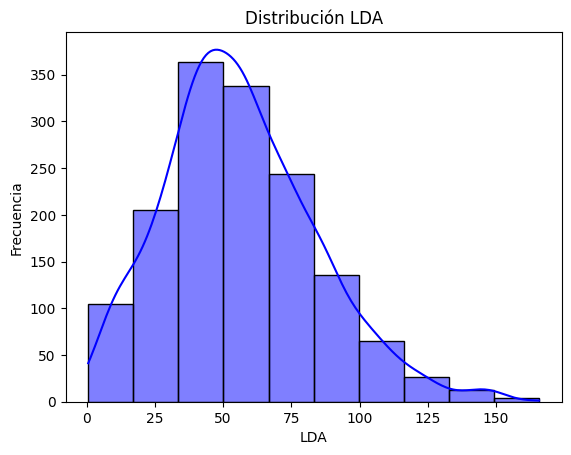

,LI,LS,ND,perdida
0,0.568346,17.091246,105.0,8.829796
1,17.091246,33.614145,205.0,25.352695
2,33.614145,50.137045,364.0,41.875595
3,50.137045,66.659945,338.0,58.398495
4,66.659945,83.182844,244.0,74.921395
5,83.182844,99.705744,136.0,91.444294
6,99.705744,116.228644,65.0,107.967194
7,116.228644,132.751544,26.0,124.490094
8,132.751544,149.274443,13.0,141.012993
9,149.274443,165.797343,4.0,157.535893


In [ ]:
#Gráficar la distribución LDA
NC=10

plt.figure()
sns.histplot(LDA,kde=True,bins=NC,color='BLUE')
plt.title('Distribución LDA')
plt.xlabel('LDA')
plt.ylabel('Frecuencia')
plt.show()

#Obtenemos la informacion de la Distribucion
counts, bin_edges = np.histogram(LDA, bins=NC)
LI =bin_edges[:-1];LS= bin_edges[1:]
mc=(LI+LS)/2 #Valor representativo de cada intervalo

#Se crea la tabla de caracterización
TAsq=np.column_stack((LI,LS,counts,mc))
df=pd.DataFrame(TAsq,columns=['LI','LS','ND','perdida'])
display(df)

In [ ]:
u=np.sum(mc*counts)/np.sum(counts)#valor esperado
print('La media de los datos es:',u)

varianza=np.sum(counts*(mc-u)**2)/np.sum(counts)
print('La varianza de los datos es:',varianza) # Mas intervalos, mas preciso

desviacion=np.sqrt(varianza)
print('La desviacion de los datos es:',desviacion)


La media de los datos es: 56.36067049807551
La varianza de los datos es: 794.299449263555
La desviacion de los datos es: 28.18331863467386


In [ ]:

#Quiero identificar datos raros o outliers
LIe=u-2*desviacion;LSe=u+2*desviacion
filas_out=np.where((LDA<LIe)|(LDA>LSe))[0]
print('Los coeficiente de outliers son:',filas_out)

Los coeficiente de outliers son: [  35  102  122  143  201  254  286  287  398  404  408  446  479  501
  532  559  578  595  648  665  713  726  765  769  793  795  817  822
  829  963  965  992 1007 1046 1105 1160 1215 1231 1232 1243 1283 1290
 1342 1343 1387 1395 1398 1409 1436]


In [ ]:
print('El coeficiente de asimetria es:',skew(LDA))
print('El coeficiente de curtosis es:',kurtosis(LDA))

#Coeficiente de asimetria
cas=np.sum(counts*(mc-u)**3)/(np.sum(counts)*desviacion**3)
print('El coeficiente de asimetria es:',cas)
vcas=(skew(LDA)-cas)/skew(LDA)
print('La variacion del coeficiente de asimentria es:',vcas*100)
#Coeficiente de Curtosis
cur=np.sum(counts*(mc-u)**4)/(np.sum(counts)*desviacion**4)-3
print('El coeficiente de curtosis es:',cur)

El coeficiente de asimetria es: 0.5654219317544418
El coeficiente de curtosis es: 0.3749822454394929
El coeficiente de asimetria es: 0.5398359603970553
La variacion del coeficiente de asimentria es: 4.525111234719186
El coeficiente de curtosis es: 0.2591591450063109


In [ ]:
PE=len(np.where(LDA<u)[0])
print('Las perdidas esperadas son:',PE)
PC=len(np.where(LDA>OpVar)[0])
print('Las perdidas catastroficas son:',PC)
PNE=len(np.where((LDA>=u)&(LDA<=OpVar))[0])
print('Las perdidas no esperadas son:',PNE)

Las perdidas esperadas son: 813
Las perdidas catastroficas son: 1
Las perdidas no esperadas son: 686


In [ ]:
OpVar=np.percentile(LDA,99.9)
print('El costo de aseguramiento de cada credito es:',OpVar)

El costo de aseguramiento de cada credito es: 149.7093186014969


# **Solicitantes Credito Año 1**

In [ ]:
nxl='/content/1. SolicitantesCrédito(USD)_Años.xlsx'
XDB4=pd.read_excel(nxl,sheet_name=5)

XDB4.head()

,Unnamed: 0,Edad,Sexo,Estado civil,Hijos,Perscargo,Nivel Renta,Estrato,Nivel de estudios,Tipo de contrato,...,Plazo,Cuota (COP),ConoCliente,Garantia,RespPat,MoraCome,PreApr,Prob.Default (PD),Score,LGD
0,6436,54,Mujer,Separado,0,1,1,3,Técnico,Indefinido,...,18,87.483415,Buenas Referencias,Codeudor,Sin Patrimonio,Mora mayor a 60 Dìas,1,0.024565,623.369751,0.457573
1,6437,28,Hombre,Casado,1,0,0,3,Tecnólogo,Ninguno,...,60,6.849567,Buenas Referencias,Con Codeudor(es),Sin Patrimonio,Con Experiencia sin Mora,0,0.113544,491.716217,0.528300
2,6438,27,NR,Soltero,1,1,1,2,Primaria,Indefinido,...,48,5.907680,Buena Experiencia CFB,Libranza Establecida,Sin Patrimonio,Con Experiencia sin Mora,0,0.140295,416.151337,0.116118
3,6439,43,Mujer,Soltero,3,3,3,2,Técnico,Ninguno,...,36,8.664364,Buena Experiencia CFB,Libranza Establecida,Prop.sin Hipoteca,Sin experiencia,0,0.289542,381.160431,0.606498
4,6440,49,Mujer,Soltero,0,1,1,2,Bachiller,Ninguno,...,3,167.064101,Buenas Referencias,Con Codeudor(es),Sin Patrimonio,Con Experiencia sin Mora,0,0.135805,378.608978,0.046469


In [ ]:
XDB4=pd.read_excel(nxl,sheet_name=5)

#Se calcula la distribucion LDA
LDA=XDB4.iloc[:,25]*XDB4.iloc[:,33]*(1+XDB4.iloc[:,35])
display(LDA)

,0
0,49.091727
1,46.807427
2,31.491289
3,111.478589
4,69.142679
...,...
1337,47.135679
1338,40.412661
1339,61.750988
1340,60.599575


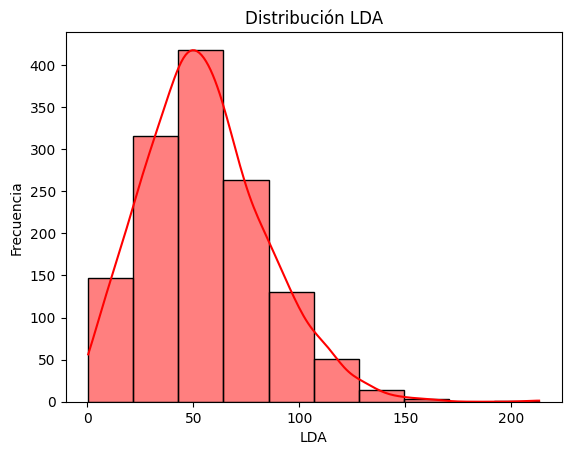

,LI,LS,ND,perdida
0,0.413092,21.695260,147.0,11.054176
1,21.695260,42.977428,315.0,32.336344
2,42.977428,64.259597,418.0,53.618513
3,64.259597,85.541765,263.0,74.900681
4,85.541765,106.823933,130.0,96.182849
5,106.823933,128.106101,51.0,117.465017
6,128.106101,149.388270,14.0,138.747186
7,149.388270,170.670438,3.0,160.029354
8,170.670438,191.952606,0.0,181.311522
9,191.952606,213.234775,1.0,202.593690


In [ ]:
#Gráficar la distribución LDA
NC=10

plt.figure()
sns.histplot(LDA,kde=True,bins=NC,color='red')
plt.title('Distribución LDA')
plt.xlabel('LDA')
plt.ylabel('Frecuencia')
plt.show()

#Obtenemos la informacion de la Distribucion
counts, bin_edges = np.histogram(LDA, bins=NC)
LI =bin_edges[:-1];LS= bin_edges[1:]
mc=(LI+LS)/2 #Valor representativo de cada intervalo

#Se crea la tabla de caracterización
TAsq=np.column_stack((LI,LS,counts,mc))
df=pd.DataFrame(TAsq,columns=['LI','LS','ND','perdida'])
display(df)

In [ ]:
u=np.sum(mc*counts)/np.sum(counts)#valor esperado
print('La media de los datos es:',u)

varianza=np.sum(counts*(mc-u)**2)/np.sum(counts)
print('La varianza de los datos es:',varianza) # Mas intervalos, mas preciso

desviacion=np.sqrt(varianza)
print('La desviacion de los datos es:',desviacion)

La media de los datos es: 55.91800167999396
La varianza de los datos es: 836.1104127631511
La desviacion de los datos es: 28.91557387919443


In [ ]:
#Quiero identificar datos raros o outliers
LIe=u-2*desviacion;LSe=u+2*desviacion
filas_out=np.where((LDA<LIe)|(LDA>LSe))[0]
print('Los coeficiente de outliers son:',filas_out)

Los coeficiente de outliers son: [  16   26   46   81   85  138  190  231  246  292  296  363  371  410
  411  467  475  495  528  571  576  597  602  613  718  796  801  828
  831  837  839  853  854  864  917 1034 1063 1099 1108 1134 1191 1228
 1330]


In [ ]:
from scipy.stats import skew, kurtosis
print('El coeficiente de asimetria es:',skew(LDA))
print('El coeficiente de curtosis es:',kurtosis(LDA))

El coeficiente de asimetria es: 0.6074481010737891
El coeficiente de curtosis es: 0.6938886954460353


In [ ]:
#Coeficiente de asimetria
cas=np.sum(counts*(mc-u)**3)/(np.sum(counts)*desviacion**3)
print('El coeficiente de asimetria es:',cas)
vcas=(skew(LDA)-cas)/skew(LDA)
print('La variacion del coeficiente de asimentria es:',vcas*100)
#Coeficiente de Curtosis
cur=np.sum(counts*(mc-u)**4)/(np.sum(counts)*desviacion**4)-3
print('El coeficiente de curtosis es:',cur)

El coeficiente de asimetria es: 0.5936899030624093
La variacion del coeficiente de asimentria es: 2.2649174451380043
El coeficiente de curtosis es: 0.49072605058951346


In [ ]:
PE=len(np.where(LDA<u)[0])
print('Las perdidas esperadas son:',PE)
PC=len(np.where(LDA>OpVar)[0])
print('Las perdidas catastroficas son:',PC)
PNE=len(np.where((LDA>=u)&(LDA<=OpVar))[0])
print('Las perdidas no esperadas son:',PNE)

Las perdidas esperadas son: 729
El costo de aseguramiento de cada credito es: 161.29129989014118
Las perdidas catastroficas son: 2
Las perdidas no esperadas son: 611


In [ ]:
OpVar=np.percentile(LDA,99.9)
print('El costo de aseguramiento de cada credito es:',OpVar)

El costo de aseguramiento de cada credito es: 161.29129989014118


#Análisis de Resultados de la Distribución de Pérdidas (LDA) por Año

1. Al revisar los datos para cada año, podemos entender mejor cómo ha evolucionado el riesgo de pérdida en los créditos:

- El Comportamiento Promedio y la Consistencia de las Pérdidas:
La Media de las pérdidas se mantiene bastante estable alrededor de los 55-56. Esto significa que, en promedio, la cantidad de dinero que se pierde por cada crédito problemático no ha variado significativamente de un año a otro.

- La Varianza mide cuánto se dispersan las pérdidas respecto a ese promedio. Vemos que este número ha disminuido constantemente. Esto es muy importante porque indica que las pérdidas son cada vez más consistentes y predecibles. Hay menos diferencia entre la pérdida más pequeña y la más grande en los años más recientes.

- La Forma del Riesgo:
La Asimetría nos dice si hay más pérdidas pequeñas o grandes. Un valor positivo indica que hay una "cola" de pérdidas más grandes a la derecha del promedio. La asimetría ha disminuido, lo que sugiere que la probabilidad de tener pérdidas extremadamente grandes se ha reducido con el tiempo.

- La Curtosis nos indica si hay muchas pérdidas alrededor del promedio y pocas pérdidas extremas (curtosis alta) o si las pérdidas están más distribuidas, con menos concentración en el centro y menos pérdidas extremas (curtosis baja o negativa). La curtosis ha bajado, lo que refuerza la idea de que las pérdidas extremas son menos probables y la distribución es menos "puntiaguda".

- Clasificación de las Pérdidas:
Las Pérdidas Esperadas (PE) son las pérdidas "normales", aquellas que están por debajo del promedio. Su número ha variado.
Las Pérdidas No Esperadas (PNE) son pérdidas mayores al promedio pero no extremas. Hemos visto un aumento en la cantidad de estas pérdidas.
Las Pérdidas Catastróficas (PC) son las pérdidas más altas y raras (por encima del percentil 99.9).

- Lo positivo es que este número se ha mantenido muy bajo y constante (siempre 2) a lo largo de los años.
El Costo de Aseguramiento (OpVar 99.9%) representa la pérdida máxima esperada en el 99.9% de los casos. Este valor ha fluctuado un poco, pero se mantiene dentro de un rango similar.

En resumen, lOS resultados nos muestran que:

Aunque el número de pérdidas "no esperadas" ha aumentado ligeramente, la tendencia general es positiva. La disminución en la varianza, asimetría y curtosis indica que el riesgo de pérdidas se ha vuelto más predecible y la probabilidad de sufrir pérdidas extremadamente grandes ha disminuido. La consistencia en el bajo número de pérdidas catastróficas es una señal tranquilizadora sobre la gestión de riesgos de la cartera de créditos.